# chip_04_test_chip_tl — 45 trilayer junction test pads (bottom × top finger sweep), on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_04_test_chip_TL.py` (`create_test_chip()`, writes `chip_04_TL_testJJ_1.0.gds`),
Quantcore internal. Spec: `docs/designs/legacy/chip_04_test_chip_tl.md`.

A 7.5 × 7.5 mm die holding a 9 × 5 array of `testPad_Nb_TL` probe structures (two 500 × 300 µm pads facing across a
300 µm gap, a trilayer cross junction between the pad tips): the bottom (straight) finger sweeps 0.4 … 1.0 µm along
the columns (drawn 0.06 µm wider, as the legacy script does), the top (bent) finger 0.4 … 0.8 µm down the rows.
Column / row labels give the finger widths in nm.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| test pads | the 45 `testPad_Nb_TL` structures (`JunctionTestPads`, preset `testPad_Nb_TL`) at the legacy positions (700 × 1200 µm pitch), legacy fingers | valued on the PDK process (R_n·A), never resized |
| bond pads | — (probe pads belong to the test structures; no bond pads or launchers) | the pad rule (`frame.pad_edge`, 100 µm) has nothing to move (step 4) |
| cheese | — (the source has none) | the **PDK band** (3 rows of 5 µm squares, 20 µm gaps, around the 3/0 keep-outs; `cheese: "auto"`), drawn by the build and kept by the fab mask |
| placement | the legacy grid | centred in the die where > 50 µm off: already centred (step 7) |
| frame | — | the PDK die frame and device ID `CHIP04 TL JJ` instead of the legacy corner `Marker`s and the layer-10 outline; the "BOT" and nm labels are not drawn |
| FEM | — | no sim groups: nothing to excite (steps 11–12 say so) |

**Reproduced exactly** (step 15): the 45 test pads at their legacy positions, each XOR-identical to the legacy script's output.

### Changes after design review (2026-11-03)

- **#1 junction values — PDK trilayer rule** (Nb, Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV, R_n 40–50 kΩ for the
  qubits): the drawn legacy test-pad fingers are kept (the sweep is the point of a test chip) and valued on the PDK
  process (R_n·A 13.5 kΩ·µm², C_J 50 fF/µm², both assumed by the PDK; 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH; R_n ∝
  1/area). The earlier assumed J_c = 1 µA/µm² is gone. Values in step 10.

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads:** none. The probe pads belong to the test structures and are not bond pads or launchers, so the pad rule
  (`frame.pad_edge`, 100 µm) has nothing to move; `C.pads_md(d)` confirms it (step 7).
- **Centring:** `L.center_circuit` (each axis only if > 50 µm off): shift (0, 0): the legacy grid is already centred.
- **Cheese:** the source has none, so the PDK band applies (`cheese: "auto"`), drawn by the build and kept by the
  fab mask.
- **Junctions:** the legacy fingers, valued on the PDK process; `pdk_rn` flags a junction outside 40–50 kΩ (only
  cells that carry lumped junction values are checked), never retuned.
- **No FEM groups** (nothing to excite): steps 11 and 12 say so.
- Educative layout: one step per stage; the steps that do not apply to a test chip (pads, routes, FEM) say so.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
from quantcore_circuits.layouts.others.test_pads import legacy_test_pad_params
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_04_test_chip_tl", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [3]:
CHEESE_NOTE = 'PDK band (auto) — the source has no cheese of its own'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — the source has no cheese of its own |

### The source's numbers

`chip_04_test_chip_TL.py`'s numbers in its own (0, 0)-centred frame (µm): the finger sweeps and the legacy
`np.arange` grids. `legacy_test_pad_params("testPad_Nb_TL", bf / 0.2, tf)` reproduces `testPad_Nb_TL.create_testPad(bf
/ 0.2, tf)` for every pad (straight finger `0.2·size + 0.06` = bf + 0.06 µm, bent finger tf).

In [4]:
# chip_04_test_chip_TL.py, legacy frame (µm)
BOTTOM_FINGER = [0.4, 0.5, 0.55, 0.6, 0.7, 0.75, 0.8, 0.9, 1.0]   # per column: create_testPad(bf / 0.2, tf)
TOP_FINGER = [0.4, 0.5, 0.6, 0.7, 0.8]                            # per row
X = [-7500 / 2 + 650 + 300 + 700 * i for i in range(9)]          # np.arange(-box/2 + 950, box/2 - 800, 700)
Y = [7500 / 2 - 1350 - 1200 * j for j in range(5)]               # np.arange(box/2 - 1350, -box/2 + 1000, -1200)
SCRIPT = "testPad_Nb_TL"
params = [legacy_test_pad_params(SCRIPT, bf / 0.2, tf) for bf in BOTTOM_FINGER for tf in TOP_FINGER]
shared = {k: v for k, v in params[0].items() if k not in ("finger_width", "second_finger_width")}

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die (the PDK standard die). The PDK frame is drawn on every
build: four L-shaped dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the
device ID `CHIP04 TL JJ` (`name_chip`; optional: the frame places it where it is free). The chip parameter
`cheese` is left at `"auto"`: the source has no cheese, so the build draws the PDK band (visible from step 5 on).

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


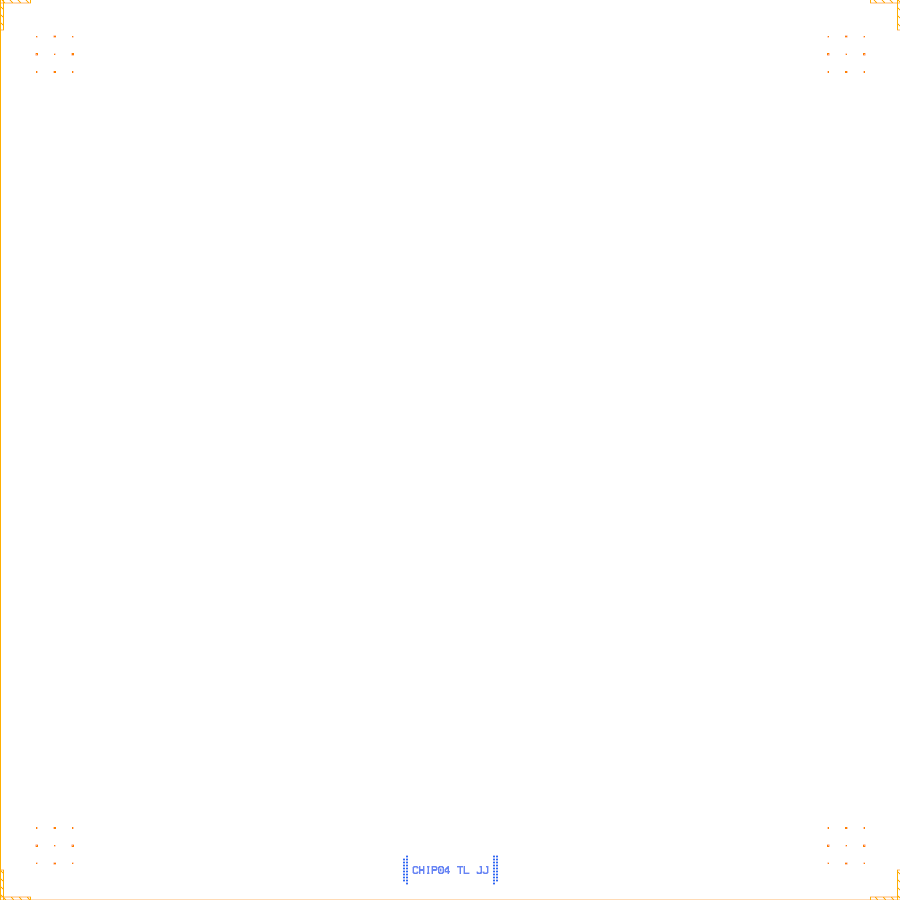

WindowsPath('build/legacy_steps/chip_04_test_chip_tl_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "CHIP04 TL JJ"}, live=LIVE)   # cheese "auto"
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule): does not apply

The PDK pad rule puts every bond pad / launcher with its outer etch `frame.pad_edge` = 100 µm from the die edge
(`edge="auto"`). This chip has none: its probe pads are part of the test structures (placed in step 5, at the
source's positions, all well inside the design area). Step 7 lists the chip's bond pads with `C.pads_md(d)`: none.

## 5 · Components: the test structures

One `d.array` of `JunctionTestPads`: a 9 × 5 grid from the first pad's legacy position at a (700, −1200) µm pitch;
`vary` sets the two finger widths per pad (column-major), `shared` the preset's other parameters. The pads have no
ports (nothing in the netlist) and carry no lumped junction values: the junction table (step 10) values the drawn
fingers.

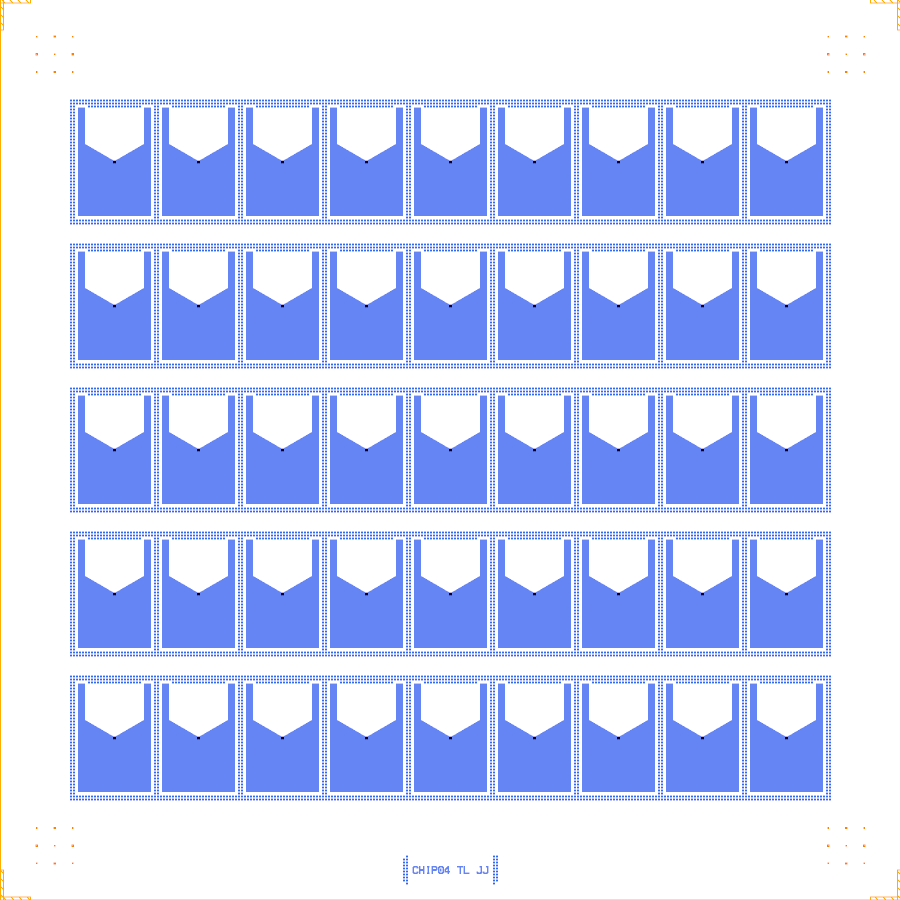

WindowsPath('build/legacy_steps/chip_04_test_chip_tl_2_testpads.png')

In [6]:
pads = d.array("TP", "JunctionTestPads", origin=L.at(X[0], Y[0]), pitch=(700, -1200), shape=(9, 5),
               vary={"finger_width": [p["finger_width"] for p in params],
                     "second_finger_width": [p["second_finger_width"] for p in params]}, **shared)
L.step_snapshot(d, "2_testpads")

## 6 · Routes: does not apply

No routes: the test structures are probed directly (needles or wire bonds on their own pads), nothing is wired on
chip.

## 7 · Cheese, pads check and centring

**Cheese.** The source has no cheese, so the build draws the **PDK band** (`cheese: "auto"`): 3 rows of 5 µm squares
with 20 µm gaps around the 3/0 keep-outs, at least 4 µm from 3/0, never over empty ground (visible in the snapshots
as the dotted rings around each structure).

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances, free text labels left out) and
shifts the design so it sits in the middle of the die, each axis only if it is more than 50 µm off. Then the design
is saved, and `C.pads_md(d)` checks the pad rule (no bond pads).

centring shift (µm): (0.0, 0.0) | <Designer chip_04_test_chip_tl: 45 instances, 0 routes, live=False> → examples\designs\legacy\chip_04_test_chip_tl.json


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

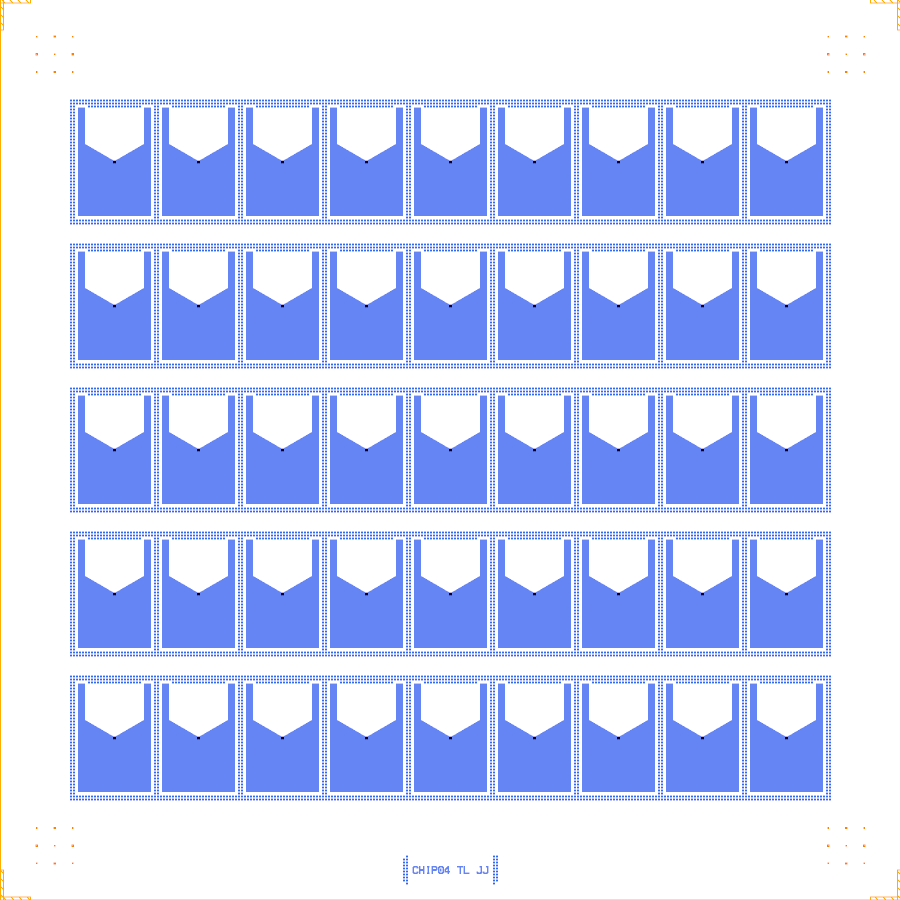

WindowsPath('build/legacy_steps/chip_04_test_chip_tl_3_centred.png')

In [7]:
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "|", d, "→", DESIGN)
display(Markdown(C.pads_md(d)))
L.step_snapshot(d, "3_centred")

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run): **DRC clean** — zero errors and no warnings: the pads have no ports and stay inside the design
area. `pdk_report`: cheese "PDK band", content centre (+0, +0) µm, junction types "—" (the test pads carry no lumped
junction values, so `pdk_rn` has nothing to check: their R_n is the table of step 10), 0 PDK design warnings. The
device ID `CHIP04 TL JJ` sits at the bottom edge centre, (3400, 100)–(4100, 400) µm.

In [8]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

DRC clean


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

The test pads are port-less probe structures without a LOM model, so the netlist is empty (only ground, no branches, nothing unconnected): there is no circuit.

In [9]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**1 nodes · 0 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |

| branch | type | nodes | estimate |
|---|---|---|---|

**Unconnected ports:** none

{'nodes': 0, 'branches': 0, 'controls': 0, 'unconnected': 0}


## 10 · LOM simulation: does not apply — the junction table instead

A test-structure chip has no qubit or resonator to simulate; the junction values follow from the drawn finger
widths: area = straight × bent finger, R_n = (R_n·A) / area, L_J from Ambegaokar–Baratoff (`circuit.bridges.
rn_from_area`, `lj_from_area`, Δ_Nb = 1.40 meV), on the PDK junction rule.

In [10]:
display(Markdown(L.junction_grid(BOTTOM_FINGER, TOP_FINGER,
                                 lambda bf, tf: (legacy_test_pad_params(SCRIPT, bf / 0.2, tf)["finger_width"], tf))))

L_J (nH) / R_n (kΩ) per test pad, drawn fingers on the PDK process. PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK). Area = straight × bent finger.

| top finger (µm) \ bottom finger (µm) | 0.4 | 0.5 | 0.55 | 0.6 | 0.7 | 0.75 | 0.8 | 0.9 | 1 |
|---|---|---|---|---|---|---|---|---|---|
| 0.4 | 10.98 / 73.4 | 9.02 / 60.3 | 8.28 / 55.3 | 7.65 / 51.1 | 6.65 / 44.4 | 6.24 / 41.7 | 5.87 / 39.2 | 5.26 / 35.2 | 4.76 / 31.8 |
| 0.5 | 8.78 / 58.7 | 7.22 / 48.2 | 6.62 / 44.3 | 6.12 / 40.9 | 5.32 / 35.5 | 4.99 / 33.3 | 4.70 / 31.4 | 4.21 / 28.1 | 3.81 / 25.5 |
| 0.6 | 7.32 / 48.9 | 6.01 / 40.2 | 5.52 / 36.9 | 5.10 / 34.1 | 4.43 / 29.6 | 4.16 / 27.8 | 3.92 / 26.2 | 3.51 / 23.4 | 3.18 / 21.2 |
| 0.7 | 6.27 / 41.9 | 5.15 / 34.4 | 4.73 / 31.6 | 4.37 / 29.2 | 3.80 / 25.4 | 3.56 / 23.8 | 3.36 / 22.4 | 3.01 / 20.1 | 2.72 / 18.2 |
| 0.8 | 5.49 / 36.7 | 4.51 / 30.1 | 4.14 / 27.7 | 3.83 / 25.6 | 3.32 / 22.2 | 3.12 / 20.8 | 2.94 / 19.6 | 2.63 / 17.6 | 2.38 / 15.9 |

**Reading the numbers** (this run): R_n runs from 73.4 kΩ (bf 0.4 → 0.46 µm drawn, tf 0.4 µm) down to 15.9 kΩ (bf 1.0,
tf 0.8 µm). The PDK window 40–50 kΩ (L_J 6.0–7.5 nH) is crossed along a diagonal: e.g. bf 0.5 / tf 0.5 (48.2 kΩ),
bf 0.55 / tf 0.5 (44.3 kΩ), bf 0.7 / tf 0.4 (44.4 kΩ), bf 0.4 / tf 0.6 (48.9 kΩ), bf 0.5 / tf 0.6 (40.2 kΩ), bf 0.4 /
tf 0.7 (41.9 kΩ).

## 11 · FEM: send the job — does not apply

A FEM job needs a sim group: a qubit / resonator cut-out with a port to excite. This chip has none (probe
structures only), so `C.export_sims(DESIGN)` exports nothing and `L.fem_send` says so. The cell stays so the
notebook has the same shape as the others (and `RUN_FEM` would have nothing to solve).

In [11]:
RUN_FEM = False                       # nothing to solve: the chip has no sim groups
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs) if jobs else "*no sim groups — nothing to export*"))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

*no sim groups — nothing to export*

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

No FEM jobs: this chip has no sim groups (nothing to excite).

## 12 · Bring the results back — does not apply

No jobs, so no results to bring back (`L.fem_bring_back` says "No FEM jobs."). On a test chip the "results" are the
probe-station R_n values, compared with the junction table of step 10.

In [12]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM jobs.

## 13 · Iterate: change one property and rebuild

A copy gives the first pad (`TP_0_0`, bf 0.4 → drawn 0.46 µm straight, tf 0.4 µm bent) the bent finger that makes its
area the PDK nominal 0.30 µm² (45 kΩ), rebuilds it and checks it: one more point of the sweep at the qubit junction.
The copy is not saved; the chip keeps the legacy sweep.

In [13]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
p = dict(d2.data["instances"]["TP_0_0"]["params"])
TF_NEW = round(0.30 / p["finger_width"], 2)                  # bent finger for the PDK nominal area (45 kΩ)
d2["TP_0_0"].set(second_finger_width=TF_NEW)
display(Markdown(L.junction_table([("TP_0_0 as drawn", p["finger_width"], p["second_finger_width"], 1),
                                   (f"TP_0_0, bent finger {TF_NEW} µm", p["finger_width"], TF_NEW, 1)])))
print("copy rebuilt:", d2.drc())

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| TP_0_0 as drawn | 0.46 × 0.4 | 1 | 0.1840 | 73.37 | 30.0 | 10.980 | 9.20 |
| TP_0_0, bent finger 0.65 µm | 0.46 × 0.65 | 1 | 0.2990 | 45.15 | 48.7 | 6.757 | 14.95 |

copy rebuilt: DRC clean


**Result** (this run): `TP_0_0` with a 0.65 µm bent finger: 0.46 × 0.65 µm = 0.299 µm², R_n 73.4 → 45.2 kΩ (L_J 10.98 →
6.76 nH); the copy rebuilds DRC clean.

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default): the build already carries the PDK band (the source has no cheese), so the mask
keeps it (`cheese_source` "build"), on 1/0 and on 3/0.

The same from a shell:

```
qcc build examples/designs/legacy/chip_04_test_chip_tl.json                    # layout → build/chip_04_test_chip_tl.oas
qcc mask  examples/designs/legacy/chip_04_test_chip_tl.json          # fab mask with the PDK rules
```

In [14]:
display(Markdown(L.fab_md(d)))

Fab mask: `build/chip_04_test_chip_tl_fab.oas` · cheese source **build** (9727 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 9783 |
| 2/0 | JJ_STRAIGHT | 45 |
| 3/0 | M3 | 9777 |
| 4/0 | JJ_BENT | 45 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 15 · Snapshots and comparison with the legacy geometry

Full chip; the top-left pad (bf 0.4, tf 0.4 µm); its junction; the bottom-right pad's junction (bf 1.0, tf 0.8 µm).

Then the same chip drawn by the author's legacy scripts (run read-only through `tests/legacy_ref`, one
`testPad_Nb_TL.create_testPad(bf / 0.2, tf)` per pad), moved by the centring shift, and the etch XOR per legacy
instance against the rebuild (PDK M1 = `base_metal_gap_wo_grid − base_metal_addition`; slivers ≤ 2 nm ignored).

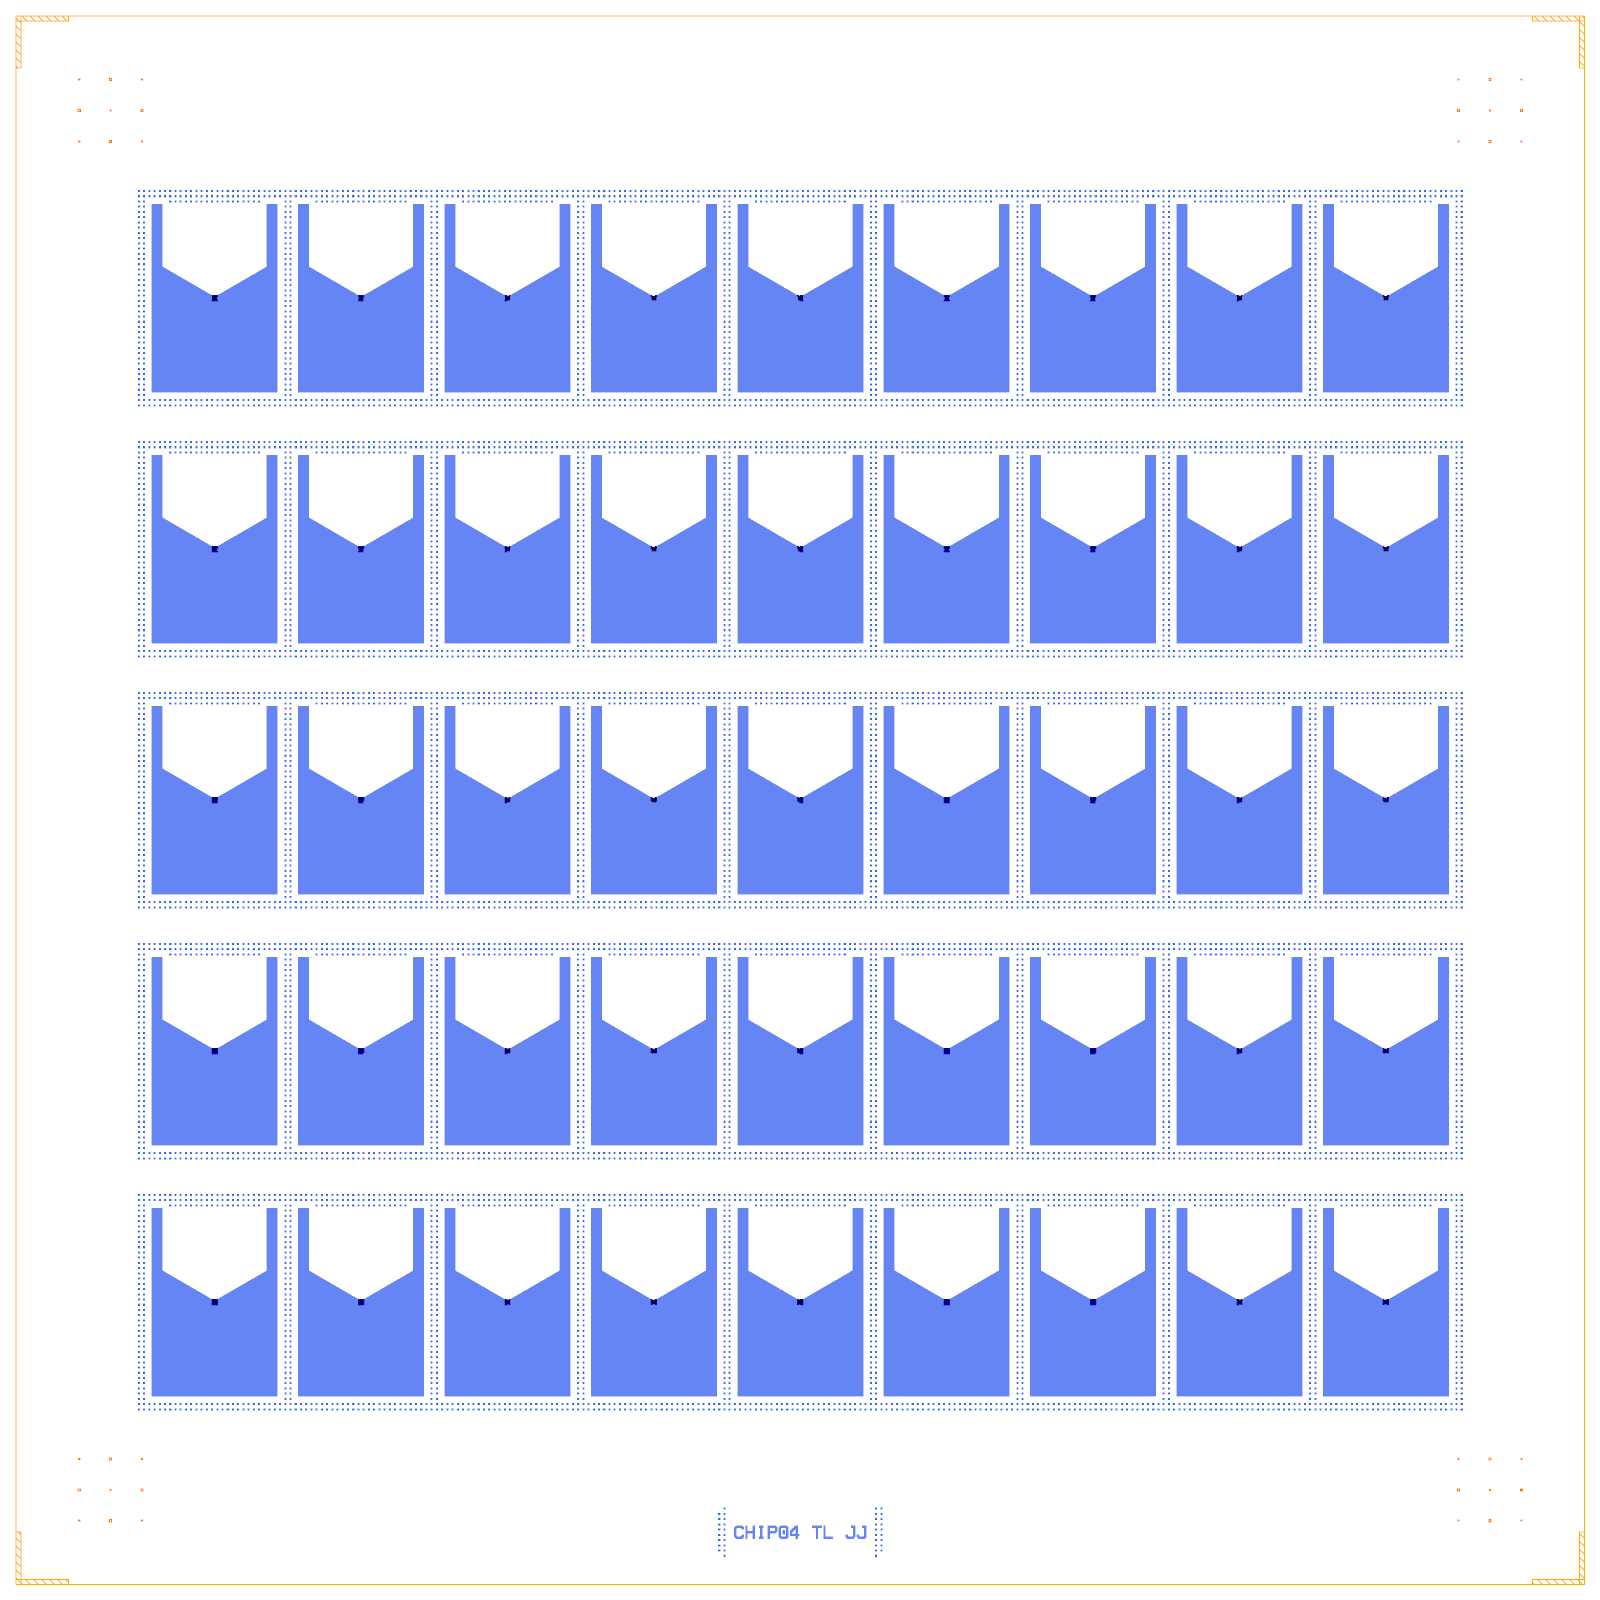

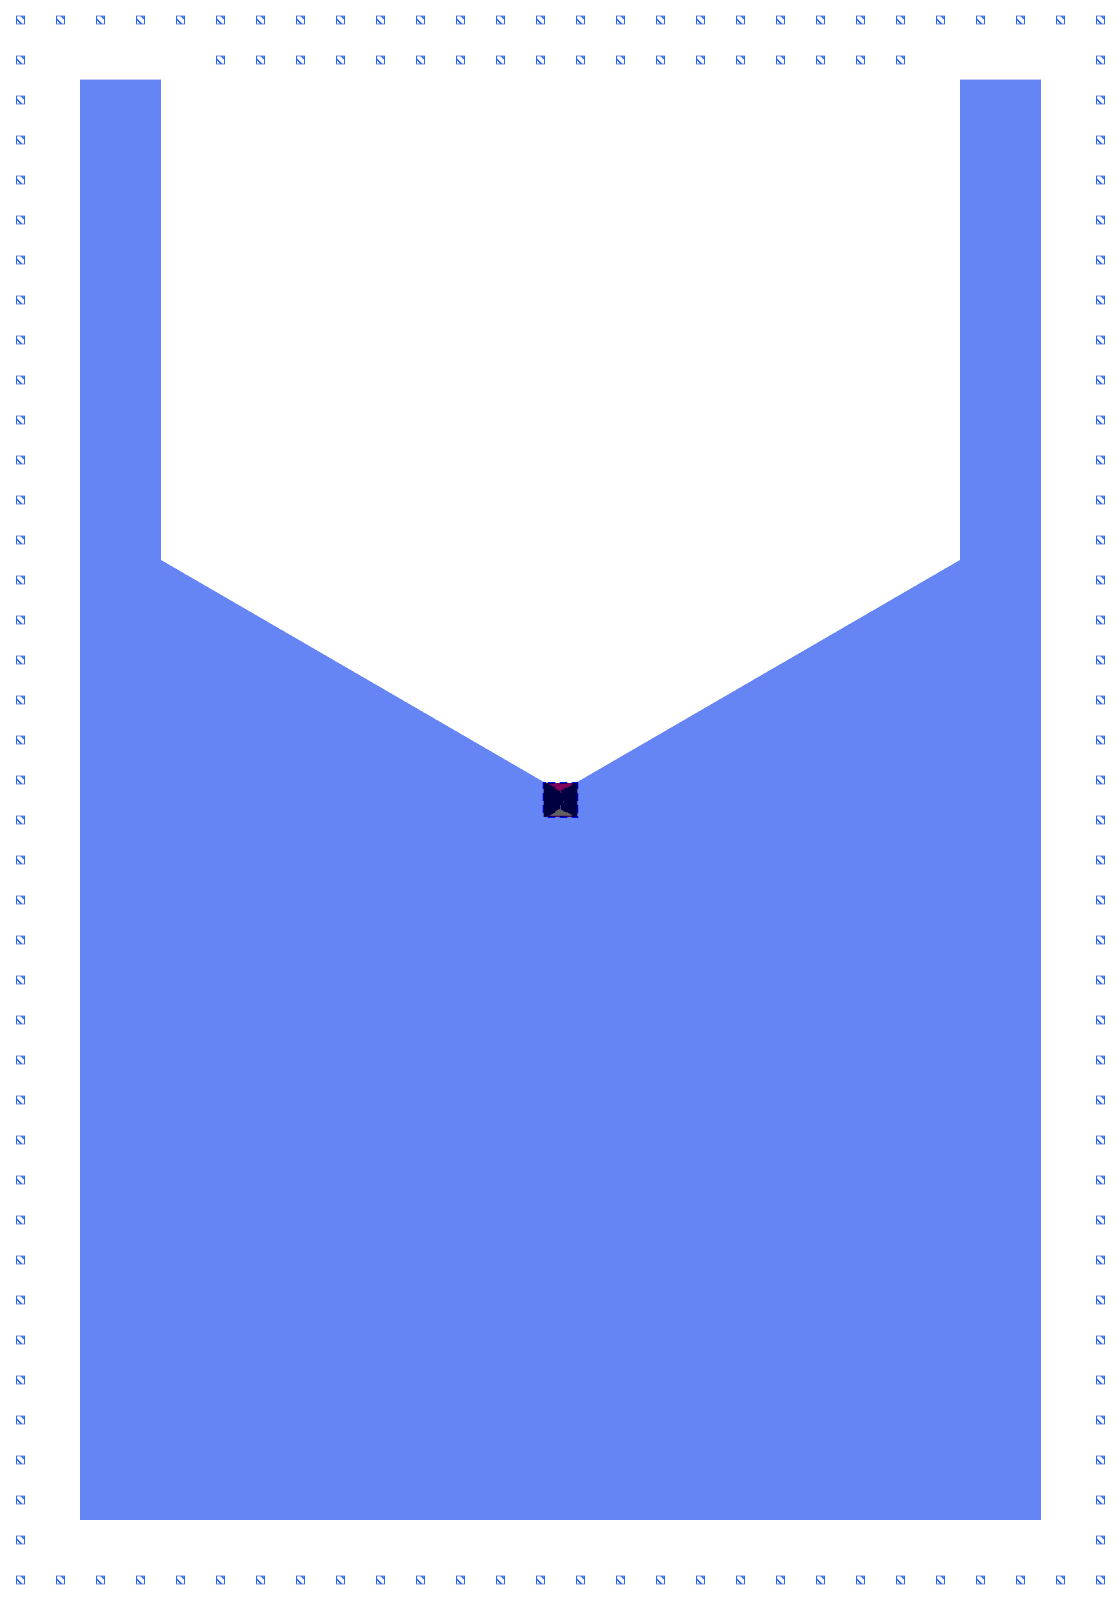

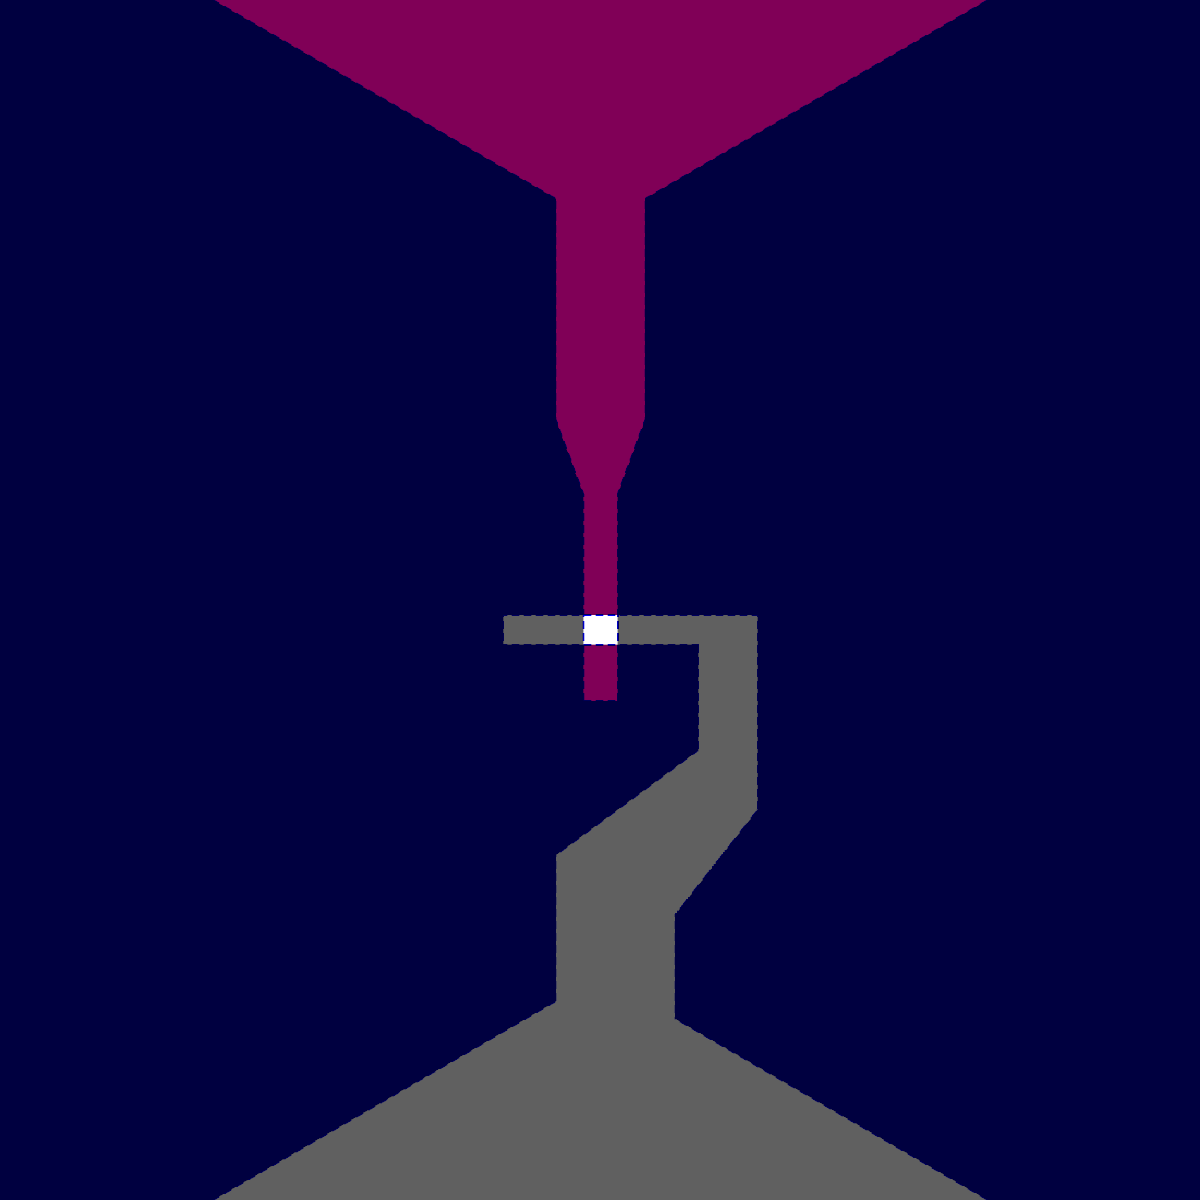

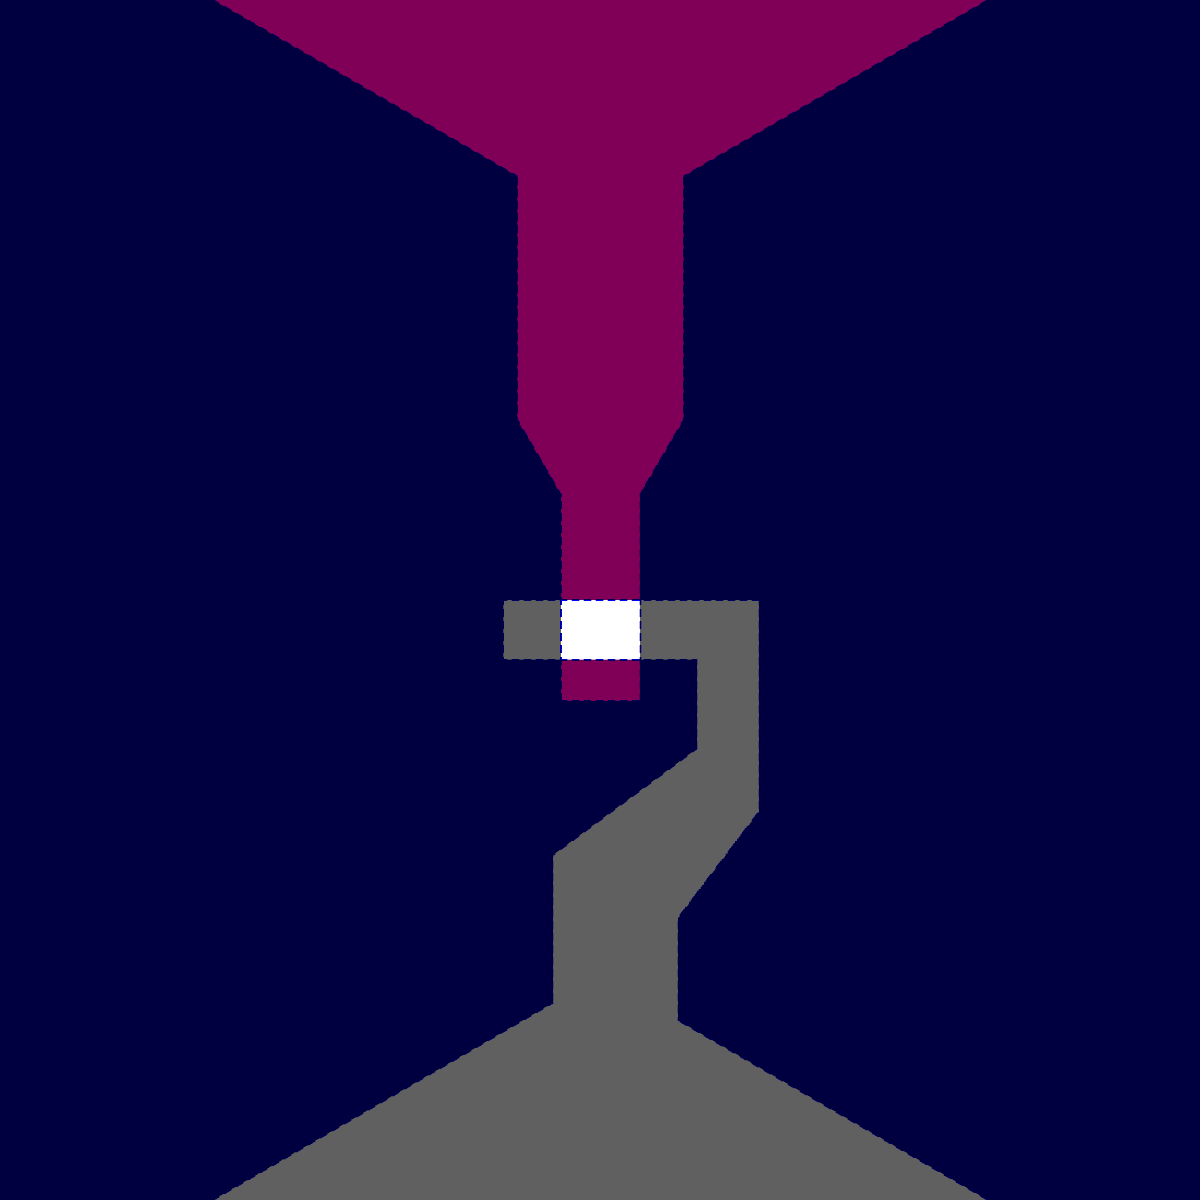

WindowsPath('examples/designs/legacy/chip_04_test_chip_tl_jj_big.png')

In [15]:
(x0, y0), (x1, y1) = L.origin(d, "TP_0_0"), L.origin(d, "TP_8_4")
C.show_snapshot(d, OUT / f"{ID}.png")
C.show_snapshot(d, OUT / f"{ID}_pad.png", box=(x0 - 350, y0 - 500, x0 + 350, y0 + 500), size=(1120, 1600), width=360)
C.show_snapshot(d, OUT / f"{ID}_jj.png", box=(x0 - 8, y0 - 8, x0 + 8, y0 + 8), size=(1200, 1200), width=360)
C.show_snapshot(d, OUT / f"{ID}_jj_big.png", box=(x1 - 8, y1 - 8, x1 + 8, y1 + 8), size=(1200, 1200), width=360)

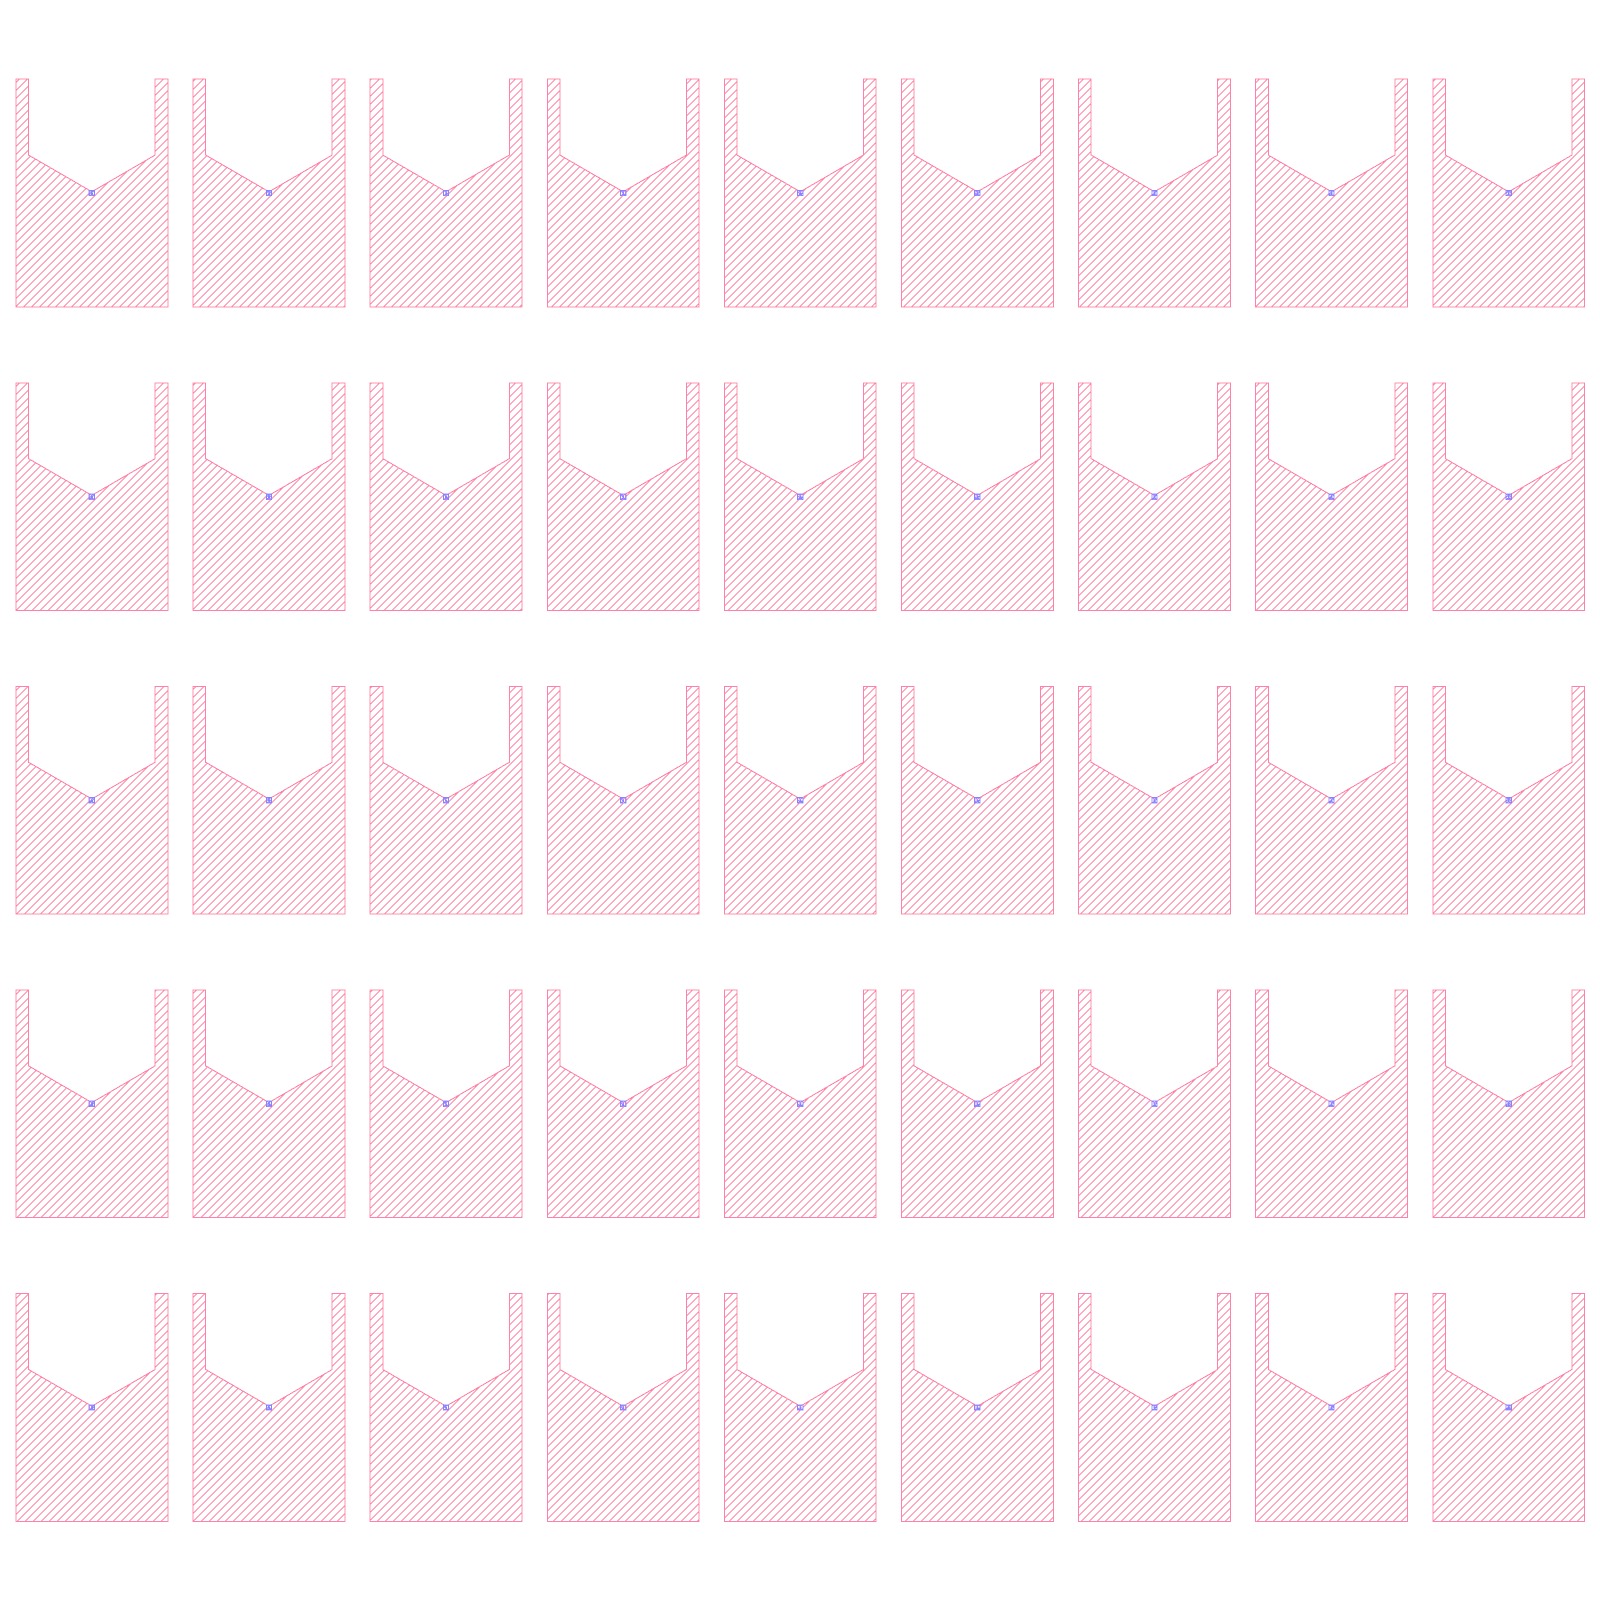

45 test pads: largest etch XOR 0.000 µm² (TP_0_0)


| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| TP_0_0 | 353393 | 353393 | 0.0 | 0.00% |
| TP_0_1 | 353393 | 353393 | 0.0 | 0.00% |
| TP_0_2 | 353393 | 353393 | 0.0 | 0.00% |
| TP_0_3 | 353393 | 353393 | 0.0 | 0.00% |
| TP_0_4 | 353393 | 353393 | 0.0 | 0.00% |
| TP_1_0 | 353393 | 353393 | 0.0 | 0.00% |
| TP_1_1 | 353393 | 353393 | 0.0 | 0.00% |
| TP_1_2 | 353393 | 353393 | 0.0 | 0.00% |
| TP_1_3 | 353393 | 353393 | 0.0 | 0.00% |
| TP_1_4 | 353393 | 353393 | 0.0 | 0.00% |
| TP_2_0 | 353393 | 353393 | 0.0 | 0.00% |
| TP_2_1 | 353393 | 353393 | 0.0 | 0.00% |
| TP_2_2 | 353393 | 353393 | 0.0 | 0.00% |
| TP_2_3 | 353393 | 353393 | 0.0 | 0.00% |
| TP_2_4 | 353393 | 353393 | 0.0 | 0.00% |
| TP_3_0 | 353393 | 353393 | 0.0 | 0.00% |
| TP_3_1 | 353393 | 353393 | 0.0 | 0.00% |
| TP_3_2 | 353393 | 353393 | 0.0 | 0.00% |
| TP_3_3 | 353393 | 353393 | 0.0 | 0.00% |
| TP_3_4 | 353393 | 353393 | 0.0 | 0.00% |
| TP_4_0 | 353393 | 353393 | 0.0 | 0.00% |
| TP_4_1 | 353393 | 353393 | 0.0 | 0.00% |
| TP_4_2 | 353393 | 353393 | 0.0 | 0.00% |
| TP_4_3 | 353393 | 353393 | 0.0 | 0.00% |
| TP_4_4 | 353393 | 353393 | 0.0 | 0.00% |
| TP_5_0 | 353393 | 353393 | 0.0 | 0.00% |
| TP_5_1 | 353393 | 353393 | 0.0 | 0.00% |
| TP_5_2 | 353393 | 353393 | 0.0 | 0.00% |
| TP_5_3 | 353393 | 353393 | 0.0 | 0.00% |
| TP_5_4 | 353393 | 353393 | 0.0 | 0.00% |
| TP_6_0 | 353393 | 353393 | 0.0 | 0.00% |
| TP_6_1 | 353393 | 353393 | 0.0 | 0.00% |
| TP_6_2 | 353393 | 353393 | 0.0 | 0.00% |
| TP_6_3 | 353393 | 353393 | 0.0 | 0.00% |
| TP_6_4 | 353393 | 353393 | 0.0 | 0.00% |
| TP_7_0 | 353393 | 353393 | 0.0 | 0.00% |
| TP_7_1 | 353393 | 353393 | 0.0 | 0.00% |
| TP_7_2 | 353393 | 353393 | 0.0 | 0.00% |
| TP_7_3 | 353393 | 353393 | 0.0 | 0.00% |
| TP_7_4 | 353393 | 353393 | 0.0 | 0.00% |
| TP_8_0 | 353393 | 353393 | 0.0 | 0.00% |
| TP_8_1 | 353393 | 353393 | 0.0 | 0.00% |
| TP_8_2 | 353393 | 353393 | 0.0 | 0.00% |
| TP_8_3 | 353393 | 353393 | 0.0 | 0.00% |
| TP_8_4 | 353393 | 353393 | 0.0 | 0.00% |

In [16]:
if L.legacy_available():
    ref = L.LegacyChip(ID)
    for i, bf in enumerate(BOTTOM_FINGER):
        for j, tf in enumerate(TOP_FINGER):
            cell = L.legacy_script_cell(SCRIPT + ".py", "create_testPad", "TEST_TL", bf / 0.2, tf,
                                        tmp=f"build/legacy_a/chip_04/{i}_{j}")
            ref.cell_from(f"TP_{i}_{j}", *cell, X[i], Y[j])
    ref = L.shift_reference(ref, *SHIFT)
    from quantcore_circuits.live.snapshot import snapshot
    snapshot(ref.write(f"build/legacy_a/{ID}_legacy.oas"), OUT / f"{ID}_legacy.png")
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=640))
    table, xor = L.xor_table(d, ref)
    print(f"{len(xor)} test pads: largest etch XOR {max(xor.values()):.3f} µm² ({max(xor, key=xor.get)})")
    display(Markdown(table))
else:
    print("components/ (legacy library) not present: no legacy reference")

## 16 · Summary

- **Matches the source:** the 45 test pads at their legacy positions, each XOR 0 µm² against the legacy
  `testPad_Nb_TL.create_testPad` output.
- **Differs, by the PDK:** the PDK die frame and device ID `CHIP04 TL JJ` (bottom centre), the PDK cheese band
  (fab cheese source "build", 9727 holes). No bond pads, so the pad rule moves nothing; centring shift (0, 0).
- **Steps that do not apply:** pads, routes, LOM simulation (no circuit: the junction table instead), FEM.
- **Open:** none (no PDK design warnings: the pads carry no lumped junction values). The 40–50 kΩ window is
  crossed by six of the 45 pads (step 10).